[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonkng/ophthalmology-ml-workshop/blob/main/notebooks/session1/Session1_Python_and_ML_Principles.ipynb)

> **Public version.** Uses openly available data only (**Harvard-GDP**, CC BY-NC-ND 4.0), downloaded
> directly from its public source when you run the notebook - nothing is redistributed here.
> Runs in Google Colab (no installation) or locally with Python 3.9+.

# Session 1 - Python, Data and the Principles of Machine Learning
**Programming in Ophthalmology - Online Workshop (Session 1, 5 November 2026)** - Dr. Simon König

This notebook is the hands-on companion to the slides. The slides explain a concept; here you
**run it on real ophthalmic data** and look at the result.

| Part | Topic | Time |
|---|---|---|
| **A** | Python & Jupyter basics, loading, merging, cleaning and visualising data | ~17 min |
| **B** | Core principles of ML: features & labels, correct train/test splits (data leakage), scaling, two interpretable models | ~23 min |

**How to use it**
- Click a cell and press `Shift + Enter` to run it. Run the cells **in order**.
- Cells marked **Your turn** contain a value you can change - change it, re-run, and see what happens.
- You cannot break anything: if something goes wrong, use *Runtime/Kernel -> Restart and run all*.
- No programming experience is needed. You are the clinical expert; the code is just a tool.

## Setup (run once)
We import a handful of **libraries** - ready-made toolkits written by others:
`pandas` (tables), `numpy` (numbers), `matplotlib`/`seaborn` (plots), `scikit-learn` (machine learning).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import ShuffleSplit, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import confusion_matrix, roc_auc_score

# plot style tuned for screen sharing
sns.set_theme(style="whitegrid", font_scale=1.15)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)

SEED = 42            # fixed random seed -> everybody gets the same numbers
print("Libraries loaded.")

Libraries loaded.


---
# Part A - Python and data (Module 1)
---
## A1. Python in 90 seconds  *(~2 min)*
A **variable** stores a value under a name, a **list** stores several values, a **function** is a
reusable recipe. That is nearly all the Python you need today.

In [2]:
# --- variables -------------------------------------------------------------
iop = 17                    # a number: intraocular pressure in mmHg
eye = "right"               # text
is_elevated = iop > 21      # True / False
print(f"IOP of the {eye} eye = {iop} mmHg -> elevated? {is_elevated}")

# --- a list ----------------------------------------------------------------
iop_values = [14, 17, 19, 24, 16]
print("measurements:", len(iop_values), "| mean:", sum(iop_values) / len(iop_values), "| max:", max(iop_values))

# --- a function + a loop ---------------------------------------------------
def classify_iop(value, cutoff=21):
    if value > cutoff:
        return "elevated"
    return "normal"

for v in iop_values:
    print(v, "->", classify_iop(v))

IOP of the right eye = 17 mmHg -> elevated? False
measurements: 5 | mean: 18.0 | max: 24
14 -> normal
17 -> normal
19 -> normal
24 -> elevated
16 -> normal


**Your turn:** change `iop` or the `cutoff` (e.g. `cutoff=18`) and re-run. The computer does exactly
what you tell it - nothing more, nothing less. That is also true of machine learning.

## A2. Loading the data  *(~3 min)*
Clinical data usually arrives as **several exports from different systems** (registration,
imaging device, perimeter, clinical record). To practise this realistic situation, we load the data
and split it back into such separate tables.

In [3]:
# ---- PUBLIC: Harvard-GDP (Luo et al., ICCV 2023), tabular part --------------------
# 1,000 patients: demographics, visual-field mean deviation (MD) and 52 total-deviation values (TD),
# and a glaucoma label. (The dataset also holds OCT RNFL thickness maps, but those are a 9.5 GB download.)
GDP_URL = "https://huggingface.co/datasets/harvardairobotics/Harvard-GDP/resolve/main/ReadMe/data_summary.csv"

master = pd.read_csv(GDP_URL)
print(f"Master table: {master.shape[0]} patients x {master.shape[1]} columns")

TD_COLS = [c for c in master.columns if c.startswith("td")]          # td1 ... td54 (52 test points)

# Split it into three "exports", exactly as they would come from three systems
KEY = ["filename"]                                                   # one eye per patient in this dataset

registration = master[KEY + ["gender", "age", "race", "hispanic"]]
vf_export    = master[KEY + ["md"] + TD_COLS].sample(frac=1, random_state=SEED)       # shuffled order!
diagnosis    = master[KEY + ["glaucoma"]].sample(frac=1, random_state=SEED + 1)       # shuffled order!

for name, t in [("registration", registration), ("vf_export", vf_export), ("diagnosis", diagnosis)]:
    print(f"{name:13s}: {t.shape[0]} rows x {t.shape[1]} columns")

Master table: 1000 patients x 67 columns
registration : 1000 rows x 5 columns
vf_export    : 1000 rows x 54 columns
diagnosis    : 1000 rows x 2 columns


In [4]:
registration.head()

,filename,gender,age,race,hispanic
0,data_0001,female,73.69,white,no
1,data_0002,female,34.48,white,no
2,data_0003,female,74.49,white,no
3,data_0004,female,35.36,white,no
4,data_0005,female,81.32,black or african american,no


**Questions to ask of every new table:** *What is one row?* (an eye? a patient? a visit?) *What are
the columns?* *Which column identifies a row (the **key**)?* Here the key is shown above:
**filename** - this public dataset has exactly one eye per patient.

In [5]:
registration.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   filename  1000 non-null   object 
 1   gender    1000 non-null   object 
 2   age       1000 non-null   float64
 3   race      1000 non-null   object 
 4   hispanic  969 non-null    object 
dtypes: float64(1), object(4)
memory usage: 39.2+ KB


**Your turn:** look at `registration.describe()` or `vf_export.head()` - what is the typical age? What
does an `MD` value look like? (Run the cell below after editing the table name.)

In [6]:
vf_export.iloc[:, :8].head()          # <- try: registration.describe(), diagnosis.head(), ...

,filename,md,td1,td2,td3,td4,td5,td6
521,data_0522,0.82,3,1,-3,-2,-2,-1
737,data_0738,0.28,-3,-6,-1,0,-1,1
740,data_0741,-0.92,-1,0,0,1,0,0
660,data_0661,-0.64,-1,-1,-5,-2,-2,-1
411,data_0412,0.33,2,2,4,3,1,0


## A3. Merging the tables  *(~3 min)*
`merge` joins tables **by key** - not by row position. This matters: the exports above arrive in
different orders.

In [7]:
# The naive approach: glue the tables side by side, row by row (by POSITION) ...
left = registration.reset_index(drop=True)
right = vf_export.reset_index(drop=True)
correct = (left[KEY] == right[KEY]).all(axis=1).mean()
print(f"Gluing by position attaches the correct visual-field row to only {correct:.1%} of eyes - silently wrong!")

Gluing by position attaches the correct visual-field row to only 0.0% of eyes - silently wrong!


In [8]:
# ... the correct approach: merge on the key, and let pandas verify that every key is unique.
data = registration
for other in (vf_export, diagnosis):
    data = data.merge(other, on=KEY, how="left", validate="one_to_one")   # 'one_to_one' = error if a key repeats

print("Merged table:", data.shape[0], "rows x", data.shape[1], "columns")
assert len(data) == len(registration), "merge changed the number of rows!"

data[["filename", "gender", "age", "race", "md", "td1", "td2", "glaucoma"]].head()

Merged table: 1000 rows x 59 columns


,filename,gender,age,race,md,td1,td2,glaucoma
0,data_0001,female,73.69,white,-10.82,-2,-2,1
1,data_0002,female,34.48,white,1.61,2,2,0
2,data_0003,female,74.49,white,1.85,4,3,0
3,data_0004,female,35.36,white,0.15,1,-2,0
4,data_0005,female,81.32,black or african american,-4.52,-6,-5,1


**Good habits:** (1) state the key, (2) use `validate=` so duplicates raise an error instead of
silently multiplying rows, (3) compare row counts before and after. A merge that "worked" but
changed the row count is the most common silent error in clinical data work.

## A4. Cleaning  *(~3 min)*
Cleaning means making **explicit, documented decisions**: what is the label, what is missing,
what is impossible? Every decision goes into a log.

In [9]:
cleaning_log = []
n0 = len(data)

# 1) The label: Harvard-GDP already provides a clean 0/1 glaucoma label
print(data["glaucoma"].value_counts().sort_index().rename({0: "0 = no glaucoma", 1: "1 = glaucoma"}).to_string())

# 2) Missing values: which columns have gaps?
print()
print(data.isna().sum()[lambda s: s > 0].to_string())

glaucoma
0 = no glaucoma    557
1 = glaucoma       443

hispanic    31


Only `hispanic` has gaps (it is a demographic descriptor that we will **not** use as a model feature).
Decision: keep those patients and mark the value as "unknown" - dropping them would cost 31 patients
for nothing. *Every such decision belongs in the log.*

In [10]:
data["hispanic"] = data["hispanic"].fillna("unknown")
cleaning_log.append(("Mark missing 'hispanic' as 'unknown' (kept)", 0, len(data)))

# 3) Tidy encodings + derived features from the 52 TD values
data["Sex"] = (data["gender"] == "male").astype(int)         # 0 = female, 1 = male
data["Age"] = data["age"]
data["Diagnosis"] = data["glaucoma"].astype(int)             # 0 = no glaucoma, 1 = glaucoma
data["patient_id"] = data["filename"]
data["MD"] = data["md"]
data["TD_mean"] = data[TD_COLS].mean(axis=1)                 # average over all test points (~ MD)
data["TD_sd"] = data[TD_COLS].std(axis=1)                    # how uneven is the field? (~ PSD-like)
data["n_depressed"] = (data[TD_COLS] <= -5).sum(axis=1)      # number of test points with TD <= -5 dB

# 4) Plausibility checks: impossible values would show up here
print(data[["Age", "MD", "TD_sd", "n_depressed"]].describe().round(1).T)
assert data["Age"].between(0, 110).all()

FEATURES = ["Age", "Sex", "MD", "TD_sd", "n_depressed"]
clean = data.reset_index(drop=True)
pd.DataFrame(cleaning_log, columns=["step", "rows removed", "rows left"])

              count  mean   std   min   25%   50%   75%   max
Age          1000.0  63.2  13.4  22.8  55.7  64.8  72.2  96.8
MD           1000.0  -3.5   5.2 -31.7  -5.4  -0.8   0.0   2.0
TD_sd        1000.0   3.5   3.1   0.9   1.4   1.7   4.8  14.7
n_depressed  1000.0  13.2  16.9   0.0   0.0   1.0  24.0  52.0


,step,rows removed,rows left
0,Mark missing 'hispanic' as 'unknown' (kept),0,1000


**Unit of analysis check** - *how many independent observations do we really have?*

In [11]:
print(f"Rows (patients/eyes): {len(clean)}")
print(f"Unique patients:      {clean['patient_id'].nunique()}")

Rows (patients/eyes): 1000
Unique patients:      1000


Here every row is one patient (one eye each), so the rows *are* independent. Real hospital
databases rarely look like this - Part B adds repeat visits so you can see why that matters.

## A5. Look before you model: visualisation  *(~4 min)*
Plots find problems (and surprises) faster than tables. Three questions: *Who is in my data? Do the
groups differ? Which variables move together?*

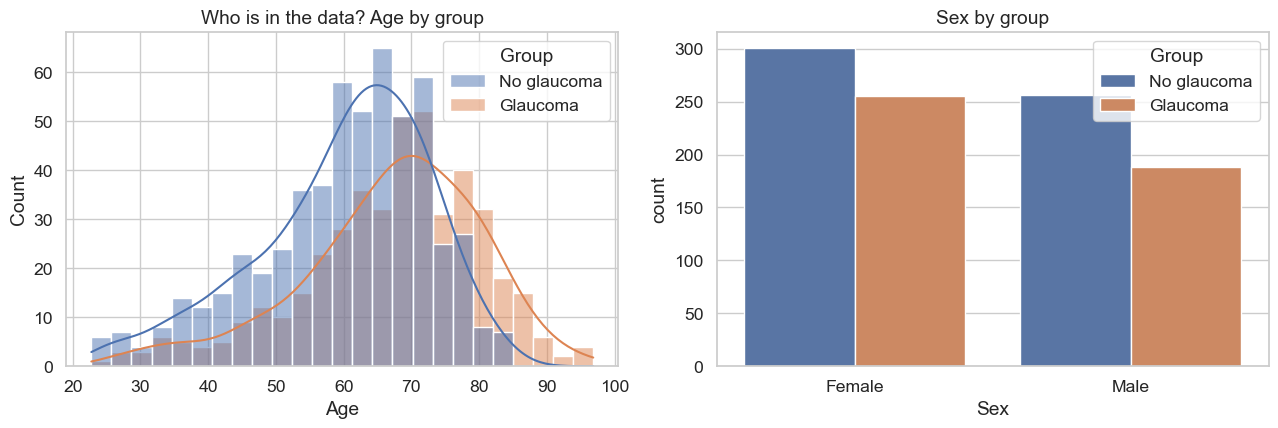

In [12]:
clean["Group"] = pd.Categorical(clean["Diagnosis"].map({0: "No glaucoma", 1: "Glaucoma"}),
                                categories=["No glaucoma", "Glaucoma"], ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=clean, x="Age", hue="Group", bins=25, kde=True, ax=axes[0])
axes[0].set_title("Who is in the data? Age by group")
sns.countplot(data=clean, x="Sex", hue="Group", ax=axes[1])
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Female", "Male"])
axes[1].set_title("Sex by group")
plt.tight_layout(); plt.show()

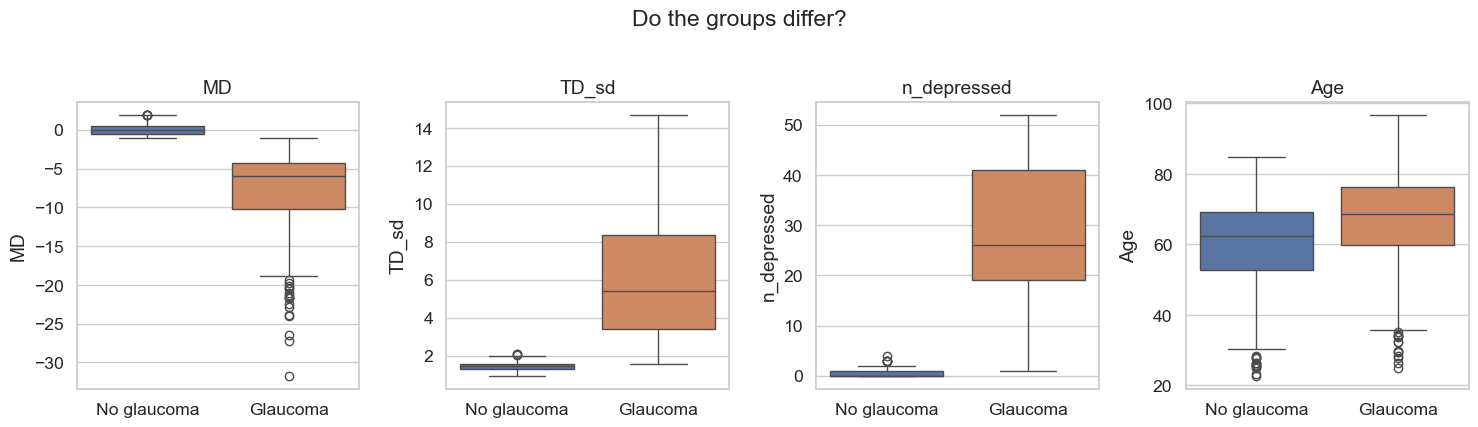

In [13]:
MEASURES = ["MD", "TD_sd", "n_depressed", "Age"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, col in zip(axes, MEASURES):
    sns.boxplot(data=clean, x="Group", y=col, hue="Group", ax=ax, legend=False)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Do the groups differ?", y=1.02)
plt.tight_layout(); plt.show()

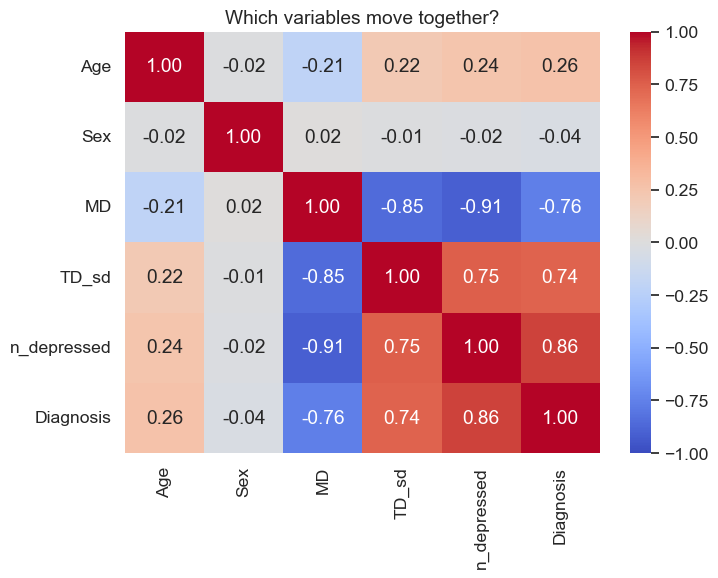

In [14]:
plt.figure(figsize=(7.5, 6))
corr = clean[FEATURES + ["Diagnosis"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Which variables move together?")
plt.tight_layout(); plt.show()

**Discuss (30 s):** Note the **sign of MD**: here (Humphrey-style) **negative MD means loss**, the
opposite of the Octopus convention. Always check the sign convention of a new dataset before you
interpret any model coefficient. Also notice how cleanly `MD`, `TD_sd` and `n_depressed` separate the
two groups - we will come back to this in B6.

---
# Part B - Core principles of machine learning (Module 2)
---
## B1. The vocabulary, on our data  *(~2 min)*

| Term | Meaning | In this notebook |
|---|---|---|
| **Features** (`X`) | the inputs the model sees | age, sex, MD, TD_sd, n_depressed |
| **Label / target** (`y`) | what we want to predict | glaucoma yes / no |
| **Training set** | data the model may learn from | ~75 % of the *patients* |
| **Test set** | data the model has never seen | ~25 % of the *patients* |
| **Model** | a function from features to a prediction | logistic regression, decision tree |
| **Overfitting** | memorising the training data instead of learning general patterns | see B2 and B5 |

### Making the public data look like a real hospital database
Harvard-GDP has one eye per patient. Real databases have **repeat visits** (and often both eyes). To
reproduce that structure for the leakage experiment in B2, we **simulate** follow-up visits for ~35 % of
patients by adding realistic test-retest noise to the visual-field values.
**This part is simulated** (everything else is real); the private research database contains such
repeat measurements naturally.

In [15]:
rng = np.random.default_rng(SEED)
repeat_patients = clean["patient_id"].sample(frac=0.35, random_state=SEED)

visits = []
for pid in repeat_patients:
    base = clean.loc[clean["patient_id"] == pid].iloc[0]
    for k in range(rng.integers(1, 4)):                          # 1-3 simulated follow-up visits
        v = base.copy()
        v[TD_COLS] = base[TD_COLS].astype(float) + rng.normal(0, 2.5, len(TD_COLS))   # test-retest noise (dB)
        v["Age"] = base["Age"] + 0.5 * (k + 1)
        v["TD_mean"] = v[TD_COLS].mean()
        v["TD_sd"] = v[TD_COLS].std()
        v["n_depressed"] = (v[TD_COLS] <= -5).sum()
        v["MD"] = base["MD"] + rng.normal(0, 0.8)
        visits.append(v)

model_data = pd.concat([clean, pd.DataFrame(visits)], ignore_index=True)
num_cols = FEATURES + ["TD_mean"] + TD_COLS
model_data[num_cols] = model_data[num_cols].astype(float)
model_data["Diagnosis"] = model_data["Diagnosis"].astype(int)
print(f"{len(clean)} real rows + {len(visits)} simulated follow-up visits = {len(model_data)} rows, "
      f"still {model_data['patient_id'].nunique()} patients")

1000 real rows + 696 simulated follow-up visits = 1696 rows, still 1000 patients


In [16]:
X = model_data[FEATURES]
y = model_data["Diagnosis"]
groups = model_data["patient_id"]          # which patient does each row belong to?

print("X (features):", X.shape, "| y (label):", y.shape, f"| glaucoma prevalence: {y.mean():.1%}")
X.head()

X (features): (1696, 5) | y (label): (1696,) | glaucoma prevalence: 42.9%


,Age,Sex,MD,TD_sd,n_depressed
0,73.69,0.0,-10.82,11.005072,26.0
1,34.48,0.0,1.61,1.262046,0.0
2,74.49,0.0,1.85,1.526043,0.0
3,35.36,0.0,0.15,1.348705,0.0
4,81.32,0.0,-4.52,1.945234,27.0


## B2. Data leakage: why the *patient*, not the row, must be split  *(~5 min)*
To judge a model honestly we test it on data it has never seen. The usual recipe - shuffle the rows,
put 75 % into training and 25 % into testing - has a trap when **one patient contributes several rows**
(both eyes, follow-up visits): the model can see the patient in training and "recognise" them in the test set.

In [17]:
# Random row split: how many test rows belong to a patient that is ALSO in the training set?
train_idx, test_idx = next(ShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(X, y))
share = groups.iloc[test_idx].isin(set(groups.iloc[train_idx])).mean()
print(f"Random ROW split:     {share:.0%} of test rows come from patients who are also in the training set.")

train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(X, y, groups))
share = groups.iloc[test_idx].isin(set(groups.iloc[train_idx])).mean()
print(f"Grouped PATIENT split: {share:.0%} of test rows come from patients who are also in the training set.")

Random ROW split:     64% of test rows come from patients who are also in the training set.
Grouped PATIENT split: 0% of test rows come from patients who are also in the training set.


Does that matter? Let's **measure** it. We use a deliberately simple model that *memorises*: for every test
eye it looks up the single most similar eye in the training data and copies its label (1-nearest-neighbour).
We run it on 20 different random splits - once splitting rows, once splitting patients - and add a
**negative control**: a **meaningless label** (a random coin flip per patient, unrelated to the eye).
A trustworthy evaluation must score **50 %** on a coin flip.

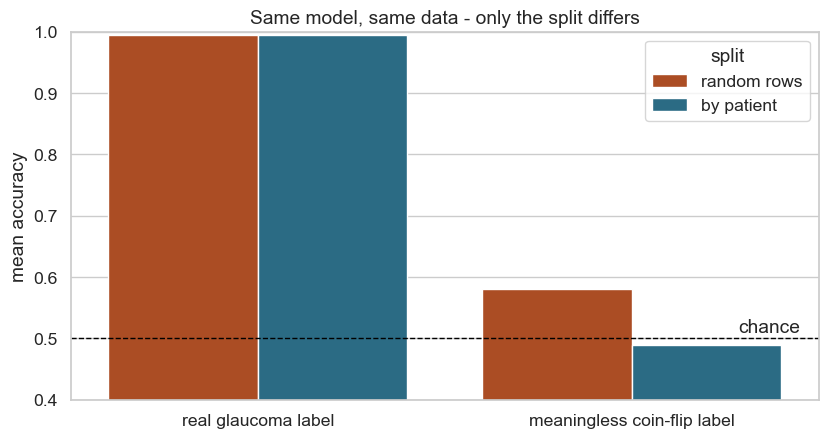

,label,split,mean accuracy,sd
0,real glaucoma label,random rows,0.994,0.003
1,real glaucoma label,by patient,0.995,0.004
2,meaningless coin-flip label,random rows,0.581,0.024
3,meaningless coin-flip label,by patient,0.489,0.016


In [18]:
def memoriser():
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))

def repeated_accuracy(target, splitter):
    scores = []
    for tr, te in splitter.split(X, target, groups):
        model = memoriser().fit(X.iloc[tr], target.iloc[tr])
        scores.append((model.predict(X.iloc[te]) == target.iloc[te]).mean())
    return np.array(scores)

# negative control: one random label per PATIENT, unrelated to any measurement
rng = np.random.default_rng(SEED)
coin = pd.Series(rng.integers(0, 2, groups.nunique()), index=groups.unique())
y_coin = groups.map(coin)

splitters = {"random rows": ShuffleSplit(20, test_size=0.25, random_state=1),
             "by patient":  GroupShuffleSplit(20, test_size=0.25, random_state=1)}

rows = []
for label_name, target in [("real glaucoma label", y), ("meaningless coin-flip label", y_coin)]:
    for split_name, sp in splitters.items():
        s = repeated_accuracy(target, sp)
        rows.append({"label": label_name, "split": split_name, "mean accuracy": s.mean(), "sd": s.std()})
leak = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
sns.barplot(data=leak, x="label", y="mean accuracy", hue="split", palette=["#C1440E", "#1C7293"], ax=ax)
ax.axhline(0.5, color="black", linestyle="--", linewidth=1); ax.text(1.45, 0.51, "chance", ha="right")
ax.set_ylim(0.4, 1.0); ax.set_xlabel(""); ax.set_title("Same model, same data - only the split differs")
plt.tight_layout(); plt.show()
leak.round(3)

**Reading the result:** on a label that is pure noise, the row split reports clearly **better than
chance** - the model has not learned any medicine, it has *recognised patients*. The patient-wise split
correctly returns ~50 %. On the real label the gap is invisible here - because this label is extremely easy to predict (see B6) - so the coin-flip control is what reveals the problem. **Rule: split by
the unit that must be independent in the future - the patient.**

**Your turn:** change `n_neighbors=1` to `15` in `memoriser()` and re-run the cell above. A model that
averages over many neighbours memorises less - what happens to the gap between the two splits?

## B3. A correct split  *(~2 min)*

In [19]:
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print(f"Training set: {len(X_train)} rows from {groups.iloc[train_idx].nunique()} patients")
print(f"Test set:     {len(X_test)} rows from {groups.iloc[test_idx].nunique()} patients")
print(f"Patients in BOTH sets: {len(overlap)}   <- must be 0")
print()
print("Glaucoma prevalence  train: {:.1%}   test: {:.1%}".format(y_train.mean(), y_test.mean()))

Training set: 945 rows from 750 patients
Test set:     751 rows from 250 patients
Patients in BOTH sets: 0   <- must be 0

Glaucoma prevalence  train: 45.7%   test: 39.3%


## B4. Feature scaling  *(~1 min)*
Features live on different scales (age in years, MD in dB, counts of test points). Models that add up weighted
features (like logistic regression) are sensitive to that, so we **standardise**: subtract the mean,
divide by the standard deviation. Crucial detail: the mean and SD are learned **on the training set only**
and then applied to the test set - otherwise information from the test set leaks into the preprocessing.

In [20]:
scaler = StandardScaler().fit(X_train)                     # learn mean / SD from the TRAINING data only
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=FEATURES, index=X_test.index)

pd.DataFrame({"mean before": X_train.mean(), "SD before": X_train.std(),
              "mean after": X_train_s.mean(), "SD after": X_train_s.std()}).round(2)

,mean before,SD before,mean after,SD after
Age,63.63,13.58,0.0,1.0
Sex,0.42,0.49,-0.0,1.0
MD,-3.69,5.22,0.0,1.0
TD_sd,3.90,3.20,-0.0,1.0
n_depressed,13.67,16.49,-0.0,1.0


Decision trees do **not** need scaling (they only ask "is this value above a threshold?"), so we will
give the tree the original, unscaled values - which also makes its rules readable in clinical units.

## B5. Two interpretable models  *(~6 min)*
**Logistic regression** = a weighted sum of the features, turned into a probability. Each weight tells
you the direction and strength of a feature's influence.
**Decision tree** = a flowchart of yes/no questions.

In [21]:
logreg = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)

def clinician_metrics(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"model": name, "accuracy": (tp + tn) / len(y_true),
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp)}

results = pd.DataFrame([
    clinician_metrics("Logistic regression", y_test, logreg.predict(X_test_s)),
    clinician_metrics("Decision tree (depth 3)", y_test, tree.predict(X_test)),
])
results.round(3)

,model,accuracy,sensitivity,specificity
0,Logistic regression,1.000,1.000,1.0
1,Decision tree (depth 3),0.995,0.986,1.0


*(Sensitivity = glaucoma eyes correctly flagged; specificity = healthy eyes correctly cleared. We
look at accuracy, ROC curves and confidence intervals properly in Session 2 - for now just see that the
models work on **unseen patients**.)*

**Suspiciously perfect?** Accuracy of ~100 % on unseen patients is *too good to be true* - hold that thought until B6.

### Reading the logistic regression

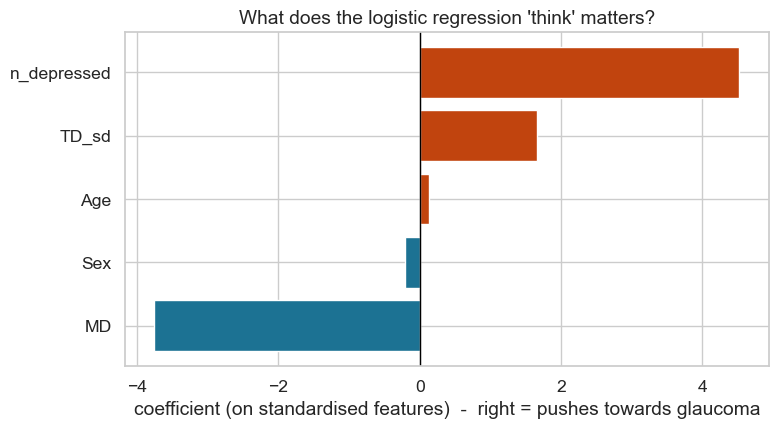

,coefficient,odds ratio per +1 SD
n_depressed,4.52,91.95
TD_sd,1.66,5.26
Age,0.13,1.14
Sex,-0.21,0.81
MD,-3.76,0.02


In [22]:
coefs = pd.Series(logreg.coef_[0], index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(coefs.index, coefs.values, color=np.where(coefs.values > 0, "#C1440E", "#1C7293"))
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("coefficient (on standardised features)  -  right = pushes towards glaucoma")
ax.set_title("What does the logistic regression 'think' matters?")
plt.tight_layout(); plt.show()

pd.DataFrame({"coefficient": coefs, "odds ratio per +1 SD": np.exp(coefs)}).round(2).iloc[::-1]

Because the features were standardised, the bars are comparable: a longer bar = a stronger effect per
"one standard deviation". The **odds ratio per +1 SD** reads like an epidemiology result: > 1 raises, < 1
lowers the odds of glaucoma, holding the other features fixed.

### Reading the decision tree

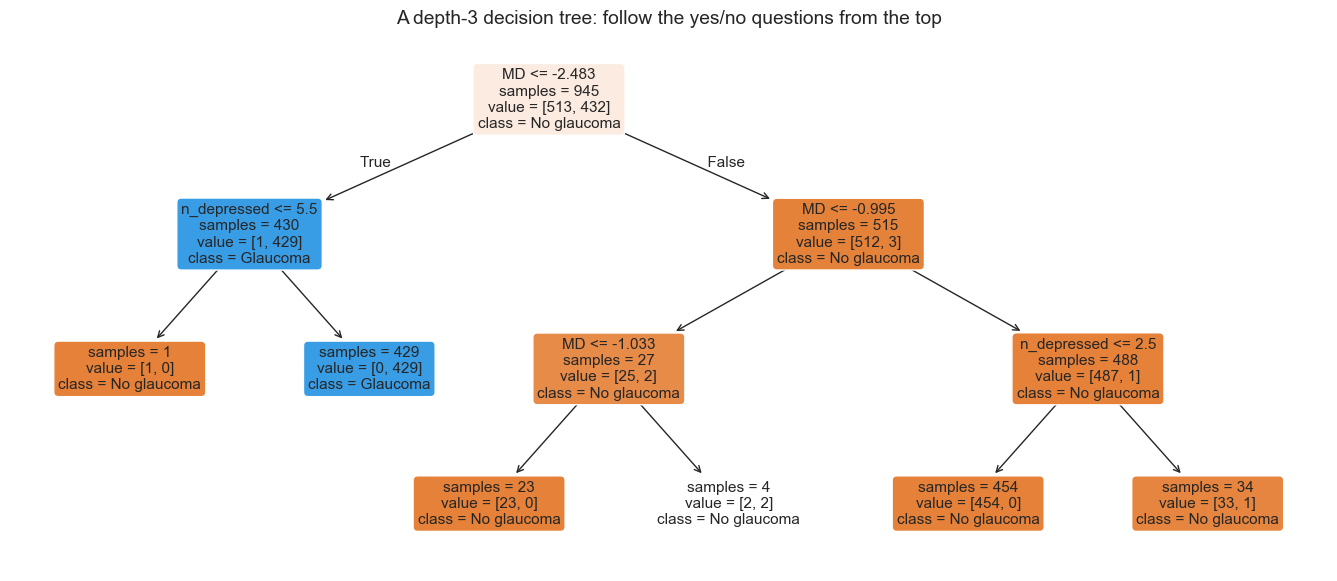

|--- MD <= -2.48
|   |--- n_depressed <= 5.50
|   |   |--- class: 0
|   |--- n_depressed >  5.50
|   |   |--- class: 1
|--- MD >  -2.48
|   |--- MD <= -1.00
|   |   |--- MD <= -1.03
|   |   |   |--- class: 0
|   |   |--- MD >  -1.03
|   |   |   |--- class: 0
|   |--- MD >  -1.00
|   |   |--- n_depressed <= 2.50
|   |   |   |--- class: 0
|   |   |--- n_depressed >  2.50
|   |   |   |--- class: 0



In [23]:
plt.figure(figsize=(17, 7))
plot_tree(tree, feature_names=FEATURES, class_names=["No glaucoma", "Glaucoma"],
          filled=True, rounded=True, fontsize=11, impurity=False)
plt.title("A depth-3 decision tree: follow the yes/no questions from the top")
plt.show()

print(export_text(tree, feature_names=FEATURES))

**Your turn:** how deep should a tree be? Change the list below and re-run. Watch the gap between
*training* and *test* accuracy open up as the tree gets deeper - that gap is **overfitting**
(Session 2 returns to this).

In [24]:
depths = [1, 2, 3, 5, 8, None]            # <- None = grow until every leaf is pure
rows = []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train, y_train)
    rows.append({"max_depth": d if d else "unlimited",
                 "train accuracy": (m.predict(X_train) == y_train).mean(),
                 "test accuracy": (m.predict(X_test) == y_test).mean()})
pd.DataFrame(rows).round(3)

,max_depth,train accuracy,test accuracy
0,1,0.996,0.995
1,2,0.997,0.995
2,3,0.997,0.995
3,5,1.000,0.989
4,8,1.000,0.989
5,unlimited,1.000,0.989


---
## End of the Session 1 material
We stopped here: you can now **merge and clean** tables, **split by patient**, **scale** correctly and fit
**two interpretable models**.

**Session 2 (12 November)** starts with a short recap and then continues with what we did not get to:
*B6 reading a model critically*, *B7 the checklist for your own analysis* and the *"spot the flaw"* cases -
followed by Module 3: **evaluating and trusting results** (confusion matrix, ROC/AUC, cross-validation,
bootstrapped confidence intervals). The Session 2 notebook is in the same repository.

## References & data
- **Harvard-GDP**: Luo Y, Shi M, Tian Y, Elze T, Wang M. *Harvard Glaucoma Detection and Progression: A Multimodal Multitask
  Dataset and Generalization-Reinforced Semi-Supervised Learning.* ICCV 2023. License: CC BY-NC-ND 4.0, non-commercial use.
  Source: https://huggingface.co/datasets/harvardairobotics/Harvard-GDP  (this notebook only reads the small metadata CSV).
- Follow-up visits in Part B are **simulated** for teaching purposes.
- Libraries: pandas, NumPy, Matplotlib, seaborn, scikit-learn.

*Teaching material only - the models are simplified examples, not validated clinical tools.*